# MATH 70112, Computing in Finance, Autumn 2026

In [1]:
import numpy as np
from statsmodels import regression
import statsmodels.api as sm
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
import math

In [2]:
# !pip install statsmodels

In [3]:
# !pip install yfinance

In [4]:
# suppress the pandas4 "inplace" warning
import warnings
from pandas.errors import Pandas4Warning
warnings.filterwarnings("ignore", category=Pandas4Warning, message=".*inplace.*")

In [5]:
aapl_df = yf.download('AAPL', start='2019-01-01', end='2021-06-12', progress=False)
aapl_df.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2019-01-02,37.436909,37.657379,36.562148,36.718610,148158800
2019-01-03,33.707932,34.544762,33.662889,34.132272,365248800
2019-01-04,35.146904,35.215654,34.089607,34.262661,234428400
2019-01-07,35.068657,35.282015,34.587420,35.251196,219111200
2019-01-08,35.737171,35.990830,35.208523,35.455066,164101200


In [6]:
spy_df = yf.download('SPY', start='2019-01-01', end='2021-06-12', progress=False)
spy_df.head()

Price,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY
Date,,,,,
2019-01-02,223.251587,224.170734,219.476892,219.503661,126925200
2019-01-03,217.924179,221.814886,217.442295,221.511472,144140700
2019-01-04,225.223694,225.866197,220.565554,220.940345,142628800
2019-01-07,226.999512,228.400516,224.599051,225.491415,103139100
2019-01-08,229.132263,229.614147,226.660425,229.176898,102512600


<Figure size 800x300 with 0 Axes>

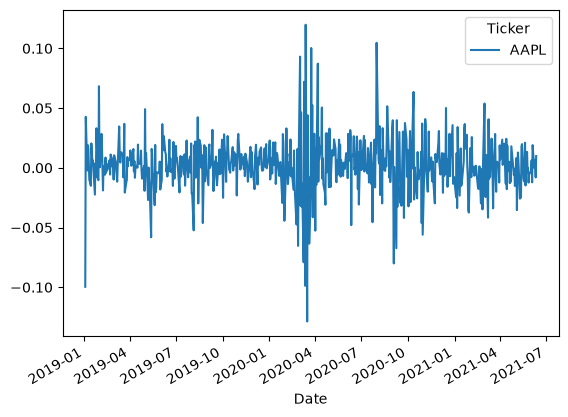

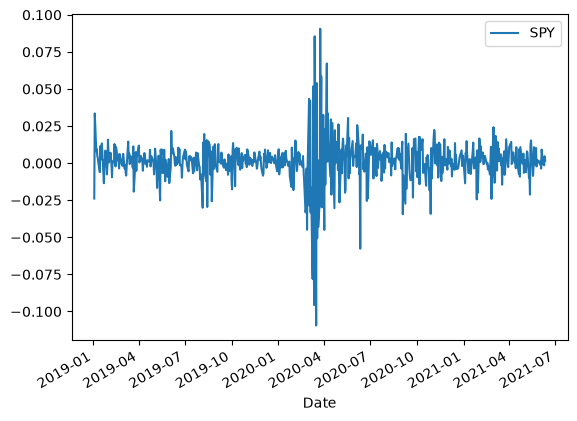

In [7]:
asset_ret = aapl_df["Close"].pct_change().dropna()
bench_ret = spy_df["Close"].pct_change().dropna()
plt.figure(figsize=(8,3))
asset_ret.plot(label="AAPL");
bench_ret.plot(label="SPY");
plt.legend()

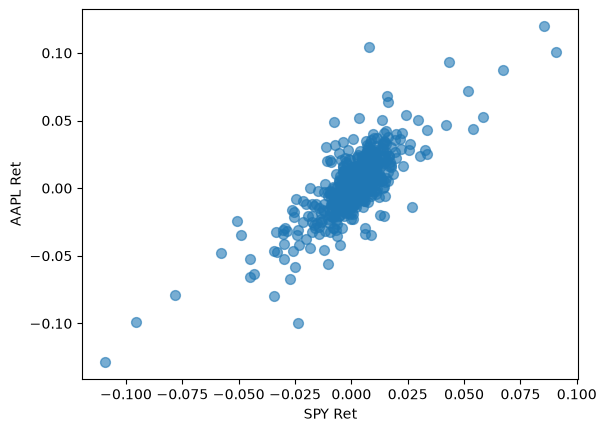

In [8]:
plt.scatter(bench_ret,asset_ret,alpha=0.6,s=50)
plt.xlabel('SPY Ret');
plt.ylabel('AAPL Ret');
plt.show()

In [9]:
AAPL = asset_ret.values
spy = bench_ret.values

# Add a constant (column of 1s for intercept)
spy_constant = sm.add_constant(spy)

# Fit regression to data
model = regression.linear_model.OLS(AAPL,spy_constant).fit()
print("Model parameters: ", model.params)
alpha , beta = model.params

Model parameters:  [9.46227667e-04 1.22144666e+00]


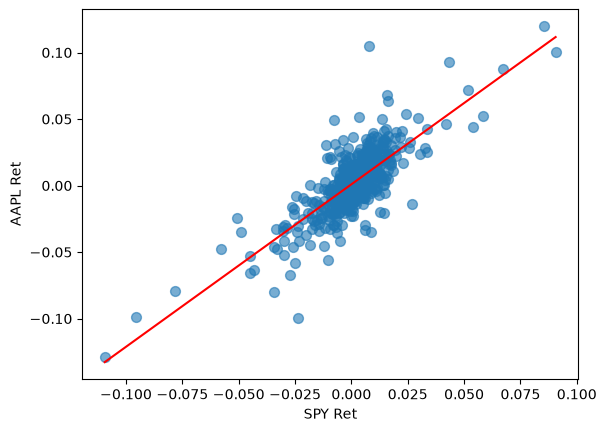

In [10]:
# Scatter Returns
plt.scatter(bench_ret,asset_ret,alpha=0.6,s=50)

# Fit Line
min_spy = bench_ret.values.min()
max_spy = bench_ret.values.max()

spy_line = np.linspace(min_spy,max_spy,100)
y = spy_line * beta + alpha

plt.plot(spy_line,y,'r')

plt.xlabel('SPY Ret')
plt.ylabel('AAPL Ret')
plt.show()

# Exercises

### 1. Plot a histogram of returns

For both AAPL and SPY

### 1.1 Sanity check whether the data seems normally distributed, or not

Calculate the first four moments ${\mathbb{E}}(X^k)$, $k = 1,2,3,4$.

Recall that, for $Z \sim N(0,1)$, then
$${\mathbb{E}}(Z) = 0, \quad
{\mathbb{E}}(Z^2) = 1, \quad
{\mathbb{E}}(Z^3) = 0, \quad
{\mathbb{E}}(Z^4) = 3$$
So if $X \sim N(\mu,\sigma^2)$, i.e. $X = \mu + \sigma Z$, for some $Z \sim N(0,1)$, then
$${\mathbb{E}}(X) = \mu, \quad
{\mathbb{E}}(X^2) = \mu^2 + \sigma^2, \quad
{\mathbb{E}}(X^3) = \mu^3 + 3 \mu \sigma^2, \quad
{\mathbb{E}}(X^4) = \mu^4 + 2 \mu^2 \sigma^2 + 3 \sigma^4$$

### 2. Autocorrelation of returns

Plot today's return against yesterdays. Perform a linear regression.

Both AAPL and SPY

### 3. Calculate volatility

(Daily return)**2

Autocorrelation of vol - plot today's vol against yesterdays

vol of AAPL vs vol of SPY

### 4. z-scores

Pick some lookback period d.
Calculate the mean $\mu$ and std dev $\sigma$ of returns over this lookback period.

Calculate the z-score of today's return $r_t$ as 
$$z_t = {\frac{r_t - \mu}{\sigma}}$$
Do you want $\mu$, $\sigma$ to be calculated including today's values, or only using values up until yesterday?

### 5. Exponentially weighted z-scores

Exponentially downweight older data

Fix some decay parameter $0 < \lambda < 1$. Impose $\lambda^k = \epsilon$, for some lookback $k$ and fixed $\epsilon$ (e.g. $\epsilon = 0.01$).

Define the (exponentially weighted) mean $\mu_t$, variance $v_t$ and std dev $\sigma_t$ by:
$$\mu_t = \lambda \mu_{t-1} + (1 - \lambda) x_t, \quad \mu_0 = x_0$$
$$v_t = \lambda v_{t-1} + (1 - \lambda) (x_t - \mu_t)^2, \quad v_0 = 0$$
$$\sigma_t = \sqrt{v_t}$$
Finally, define the (exponentially weighted) z-score by
$$z_t = {\frac{(x_t - \mu_t)}{\sigma_t}}, \quad z_0 = 0$$